# Вариант 7. Изгиб консольной балки Эйлера — Бернулли методом PINN
Решаем $w^{(4)}+1=0$ на $[0,1]$, $w(0)=w'(0)=w''(1)=w'''(1)=0$. Сравниваем мягкие условия с весами 1 и 100 и встроенные условия. Эталон используется только для тестирования.

In [1]:

import torch
from torch import nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from pathlib import Path
from IPython.display import display

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
SEED = 42
N_TRAIN, N_TEST = 300, 200
EPOCHS, LR = 2000, 0.001
EI = 1.0  # безразмерная жёсткость
out = Path('PINN_beam_results')
out.mkdir(exist_ok=True)


## 1. Точное решение и независимые точки коллокации

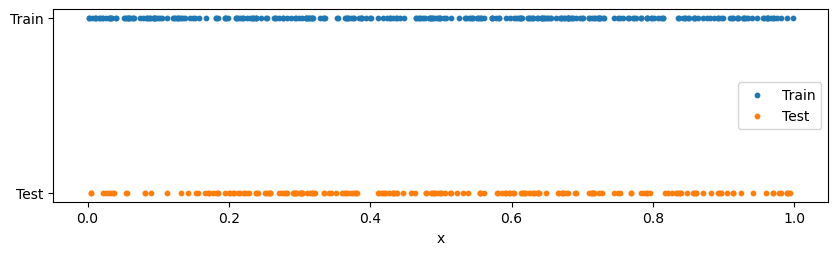

In [2]:
def exact(x):
    w = -x**4/24 + x**3/6 - x**2/4
    w1 = -x**3/6 + x**2/2 - x/2
    w2 = -x**2/2 + x - 0.5
    w3 = 1-x
    w4 = -torch.ones_like(x)
    return [w, w1, w2, w3, w4, -EI*w2, -EI*w3]

# Разные генераторы: тестовые точки не участвуют в обучении.
x_train = torch.rand(N_TRAIN, 1, generator=torch.Generator().manual_seed(SEED)).clamp(1e-8, 1-1e-8)
x_test = torch.rand(N_TEST, 1, generator=torch.Generator().manual_seed(SEED+1)).sort(dim=0).values
plt.figure(figsize=(10,2.5))
plt.scatter(x_train.numpy(), np.ones(N_TRAIN), s=10, label='Train')
plt.scatter(x_test.numpy(), np.zeros(N_TEST), s=10, label='Test')
plt.yticks([0,1], ['Test','Train']); plt.xlabel('x'); plt.legend(); plt.show()


## 2. Архитектура и автоматическое дифференцирование

In [3]:
def derivative(y, x, order=1):
    # create_graph сохраняет граф для следующих производных и обучения.
    for _ in range(order):
        y = torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]
    return y

class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        # tanh гладкая, поэтому подходит для производных до 4-го порядка.
        self.net = nn.Sequential(nn.Linear(1,32), nn.Tanh(),
                                 nn.Linear(32,32), nn.Tanh(), nn.Linear(32,1))
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)
    def forward(self, x):
        return self.net(x)

x = torch.tensor([[0.5]], requires_grad=True)
assert abs(derivative(x**4,x,4).item()-24)<1e-12
print('Проверка autograd пройдена')


Проверка autograd пройдена


## 3. Граничные условия
Для Hard BC положим $v=x^2N_\theta(x)$ и $w=v-x^2v''(1)/2+(x^2/2-x^3/6)v'''(1)$. Эта коррекция удовлетворяет всем четырём условиям и не меняет четвёртую производную.

In [4]:
def predict(model, x, mode):
    if mode == 'soft':
        return model(x)
    v = x**2 * model(x)
    # Независимая координата правой границы.
    b = torch.ones((1,1), requires_grad=True)
    vb = b**2 * model(b)
    A = derivative(vb,b,2)
    B = derivative(A,b)
    return v - x**2*A/2 + (x**2/2-x**3/6)*B

def boundary_residuals(model, mode):
    a = torch.zeros((1,1), requires_grad=True)
    b = torch.ones((1,1), requires_grad=True)
    wa, wb = predict(model,a,mode), predict(model,b,mode)
    d2 = derivative(wb,b,2)
    return torch.cat([wa, derivative(wa,a), d2, derivative(d2,b)])

def equation_loss(model, x, mode):
    x = x.detach().clone().requires_grad_(True)
    # Полиномиальная коррекция Hard BC исчезает при 4-м дифференцировании.
    w = x**2*model(x) if mode=='hard' else model(x)
    return (derivative(w,x,4)+1).square().mean()

torch.manual_seed(SEED)
check = PINN()
print('Hard BC до обучения:', boundary_residuals(check,'hard').detach().numpy().ravel())
assert boundary_residuals(check,'hard').abs().max().item()<1e-10


Hard BC до обучения: [0.00000000e+00 0.00000000e+00 1.11022302e-16 0.00000000e+00]


## 4. Обучение трёх моделей
Для Soft BC минимизируем сумму невязки уравнения и взвешенной суммы квадратов граничных невязок. Для Hard BC — только невязку уравнения.

In [5]:
def train_pinn(mode, weight):
    torch.manual_seed(SEED)  # одинаковая начальная инициализация
    model = PINN()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = []
    start = time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        optimizer.zero_grad()
        ode = equation_loss(model,x_train,mode)
        bc = boundary_residuals(model,mode).square().sum()
        loss = ode + weight*bc if mode=='soft' else ode
        loss.backward()  # градиенты по параметрам сети, а не по координате
        optimizer.step()
        history.append([epoch,loss.item(),ode.item(),bc.item()])
        if epoch==1 or epoch%200==0:
            print(f'{epoch:4d}: ODE={ode.item():.3e}, BC={bc.item():.3e}')
    return model.eval(), pd.DataFrame(history,columns=['epoch','total','ode','bc']), time.perf_counter()-start

configs = {'Soft BC (1)':('soft',1.), 'Soft BC (100)':('soft',100.), 'Hard BC':('hard',0.)}
models, histories, times = {}, {}, {}
for name,(mode,weight) in configs.items():
    print(name)
    models[name],histories[name],times[name] = train_pinn(mode,weight)
    print(f'Время: {times[name]:.2f} с')
print('Общее время обучения:',sum(times.values()),'с')


Soft BC (1)
   1: ODE=1.486e+00, BC=1.356e-01
 200: ODE=5.845e-02, BC=7.713e-02
 400: ODE=7.402e-03, BC=3.167e-03
 600: ODE=4.803e-03, BC=7.256e-04
 800: ODE=2.908e-03, BC=2.213e-04
1000: ODE=1.539e-03, BC=7.203e-05
1200: ODE=5.789e-04, BC=1.955e-05
1400: ODE=1.360e-04, BC=3.339e-06
1600: ODE=7.879e-05, BC=5.598e-07
1800: ODE=6.483e-05, BC=2.689e-07
2000: ODE=5.422e-05, BC=1.890e-07
Время: 52.66 с
Soft BC (100)
   1: ODE=1.486e+00, BC=1.356e-01
 200: ODE=5.813e-01, BC=2.389e-04
 400: ODE=1.891e-01, BC=8.251e-05
 600: ODE=2.060e-02, BC=3.019e-06
 800: ODE=1.674e-02, BC=6.477e-07
1000: ODE=1.390e-02, BC=4.448e-07
1200: ODE=1.132e-02, BC=3.429e-07
1400: ODE=8.934e-03, BC=2.689e-07
1600: ODE=6.290e-03, BC=2.036e-07
1800: ODE=3.383e-03, BC=1.293e-07
2000: ODE=1.097e-03, BC=4.817e-08
Время: 39.24 с
Hard BC
   1: ODE=4.934e-01, BC=1.233e-32
 200: ODE=1.525e-04, BC=5.624e-32
 400: ODE=9.172e-05, BC=3.081e-33
 600: ODE=5.732e-05, BC=6.163e-33
 800: ODE=4.659e-05, BC=2.850e-32
1000: ODE=4.290e-0

## 5. Проверка на 200 независимых узлах

In [6]:
keys = ['w','w1','w2','w3','w4','M','Q']
def evaluate(model,x,mode):
    x = x.detach().clone().requires_grad_(True)
    values = [predict(model,x,mode)]
    for _ in range(4):
        values.append(derivative(values[-1],x))
    values += [-EI*values[2],-EI*values[3]]
    return {k:v.detach().numpy().ravel() for k,v in zip(keys,values)}

truth = {k:v.numpy().ravel() for k,v in zip(keys,exact(x_test))}
results = {name:evaluate(model,x_test,configs[name][0]) for name,model in models.items()}
def rmse(a,b): return np.sqrt(np.mean((a-b)**2))
rows, bc_rows, summary = [], [], []
for name,r in results.items():
    for k in keys:
        e = r[k]-truth[k]
        rows.append([name,k,rmse(r[k],truth[k]),100*np.linalg.norm(e)/np.linalg.norm(truth[k]),np.max(np.abs(e))])
    bc = boundary_residuals(models[name],configs[name][0]).detach().numpy().ravel()
    bc_rmse = np.sqrt(np.mean(bc**2))
    bc_rows.append([name,*bc,bc_rmse])
    summary.append([name,rmse(r['w'],truth['w']),rmse(r['w1'],truth['w1']),rmse(r['M'],truth['M']),np.sqrt(np.mean((r['w4']+1)**2)),bc_rmse,times[name]])
metrics_df = pd.DataFrame(rows,columns=['Модель','Величина','RMSE','L2 relative (%)','Max error'])
bc_df = pd.DataFrame(bc_rows,columns=['Модель','w(0)',"w'(0)","w''(1)","w3(1)",'BC RMSE'])
summary_df = pd.DataFrame(summary,columns=['Модель','RMSE w',"RMSE w'",'RMSE M','ODE RMSE','BC RMSE','Время, сек'])
display(metrics_df,bc_df,summary_df)


,Модель,Величина,RMSE,L2 relative (%),Max error
0,Soft BC (1),w,0.000092,0.152722,0.000191
1,Soft BC (1),w1,0.000194,0.144025,0.000327
2,Soft BC (1),w2,0.000253,0.120361,0.000392
3,Soft BC (1),w3,0.000537,0.094311,0.000987
4,Soft BC (1),w4,0.008423,0.842293,0.036230
5,Soft BC (1),M,0.000253,0.120361,0.000392
6,Soft BC (1),Q,0.000537,0.094311,0.000987
7,Soft BC (100),w,0.001079,1.786676,0.002306
8,Soft BC (100),w1,0.002523,1.874400,0.003480
9,Soft BC (100),w2,0.003874,1.843758,0.007031


,Модель,w(0),w'(0),w''(1),w3(1),BC RMSE
0,Soft BC (1),0.000008,0.000091,2.887350e-04,0.000359,2.348863e-04
1,Soft BC (100),0.000004,0.000037,2.133977e-04,0.000030,1.093466e-04
2,Hard BC,0.000000,0.000000,-5.551115e-17,0.000000,2.775558e-17


,Модель,RMSE w,RMSE w',RMSE M,ODE RMSE,BC RMSE,"Время, сек"
0,Soft BC (1),0.000092,0.000194,0.000253,0.008423,2.348863e-04,52.661052
1,Soft BC (100),0.001079,0.002523,0.003874,0.033589,1.093466e-04,39.240649
2,Hard BC,0.000020,0.000045,0.000080,0.005151,2.775558e-17,66.081929


## 6. Графики

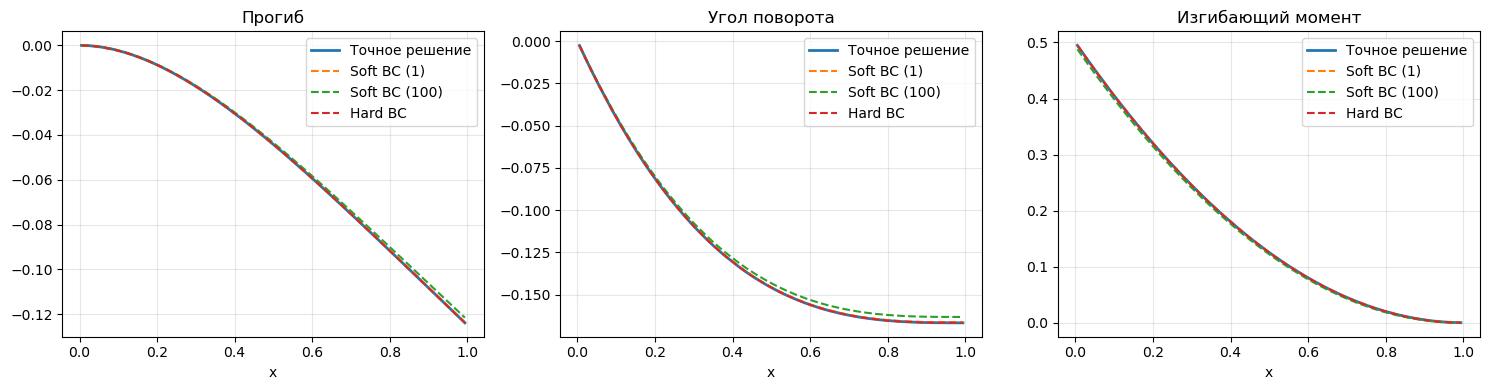

In [7]:
def plot_quantities(items, filename, error=False):
    fig, axes = plt.subplots(1,len(items),figsize=(5*len(items),4))
    for ax,(k,title) in zip(np.atleast_1d(axes),items):
        if not error:
            ax.plot(x_test.numpy().ravel(),truth[k],label='Точное решение',linewidth=2)
        for name,r in results.items():
            y = np.maximum(np.abs(r[k]-truth[k]),1e-16) if error else r[k]
            ax.plot(x_test.numpy().ravel(),y,'--',label=name)
        if error: ax.set_yscale('log')
        ax.set_title(title); ax.set_xlabel('x'); ax.grid(alpha=.3); ax.legend()
    fig.tight_layout(); fig.savefig(out/filename,dpi=200); plt.show()

plot_quantities([('w','Прогиб'),('w1','Угол поворота'),('M','Изгибающий момент')],'01_beam_solution.png')


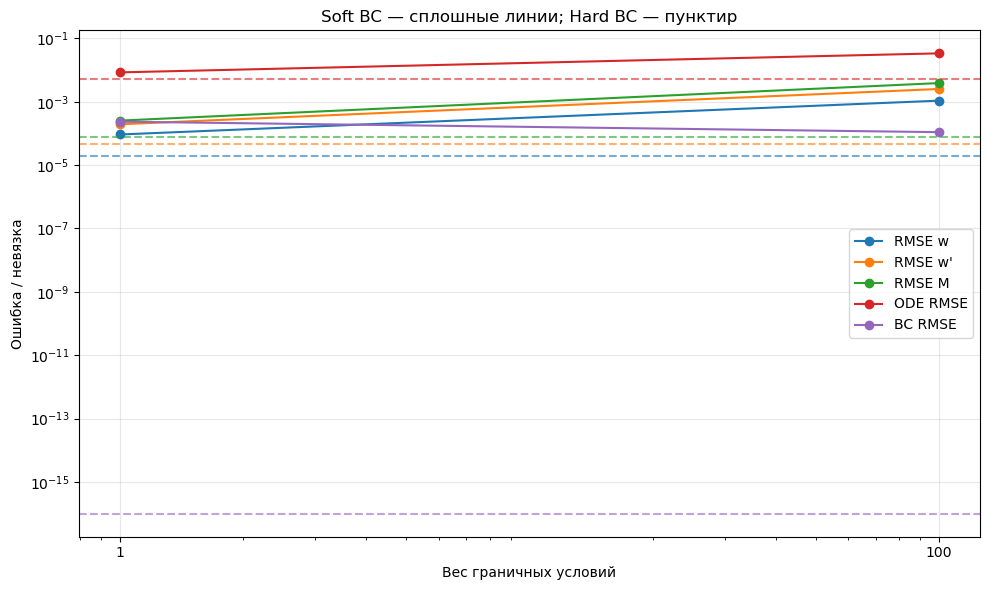

In [8]:
s = summary_df.set_index('Модель')
plt.figure(figsize=(10,6))
for k in ['RMSE w',"RMSE w'",'RMSE M','ODE RMSE','BC RMSE']:
    line, = plt.plot([1,100],np.maximum(s.loc[['Soft BC (1)','Soft BC (100)'],k],1e-16),'o-',label=k)
    plt.axhline(max(s.loc['Hard BC',k],1e-16),ls='--',color=line.get_color(),alpha=.6)
plt.xscale('log'); plt.yscale('log'); plt.xticks([1,100],['1','100'])
plt.xlabel('Вес граничных условий'); plt.ylabel('Ошибка / невязка')
plt.title('Soft BC — сплошные линии; Hard BC — пунктир')
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.savefig(out/'02_boundary_weights.png',dpi=200); plt.show()


## 7. Дополнительные графики

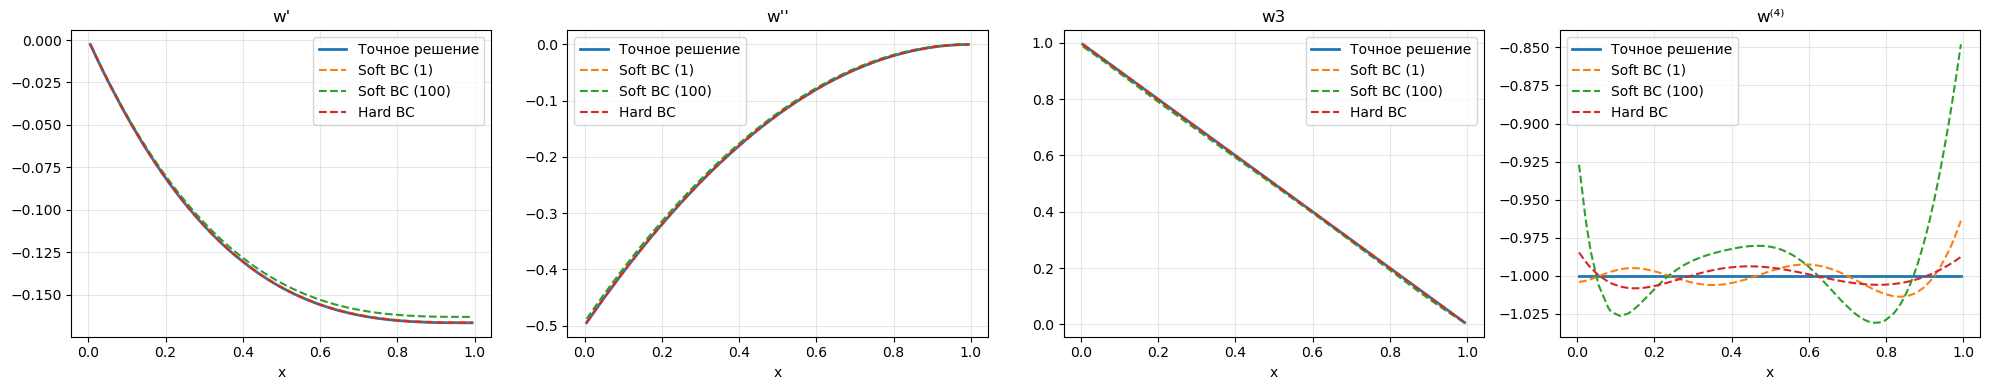

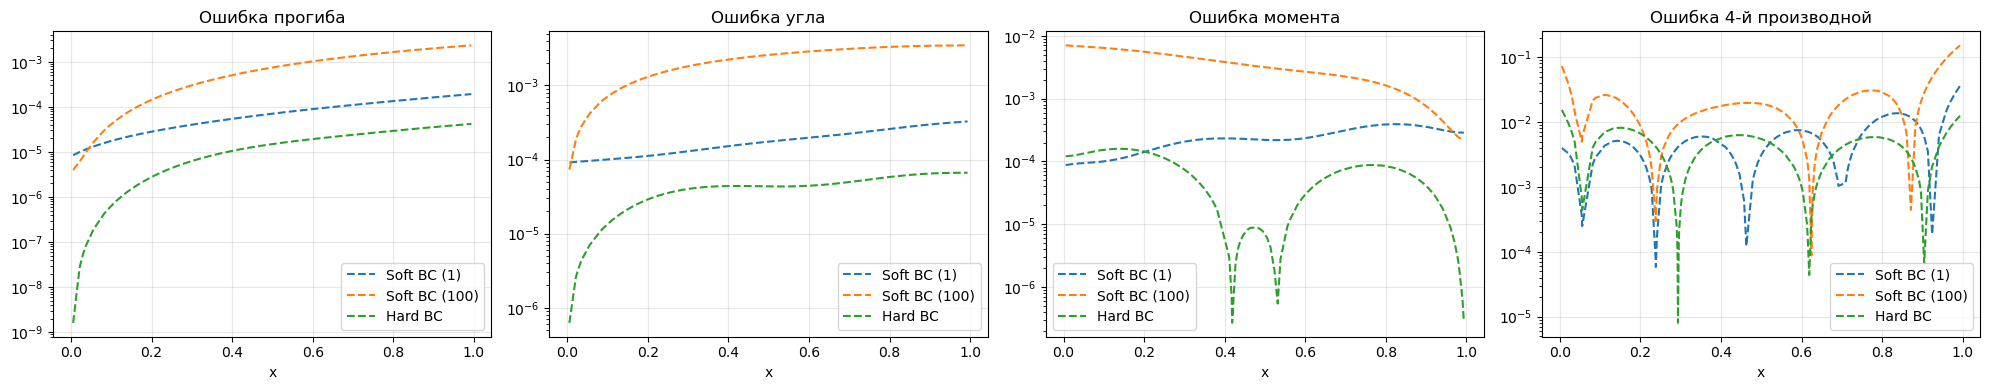

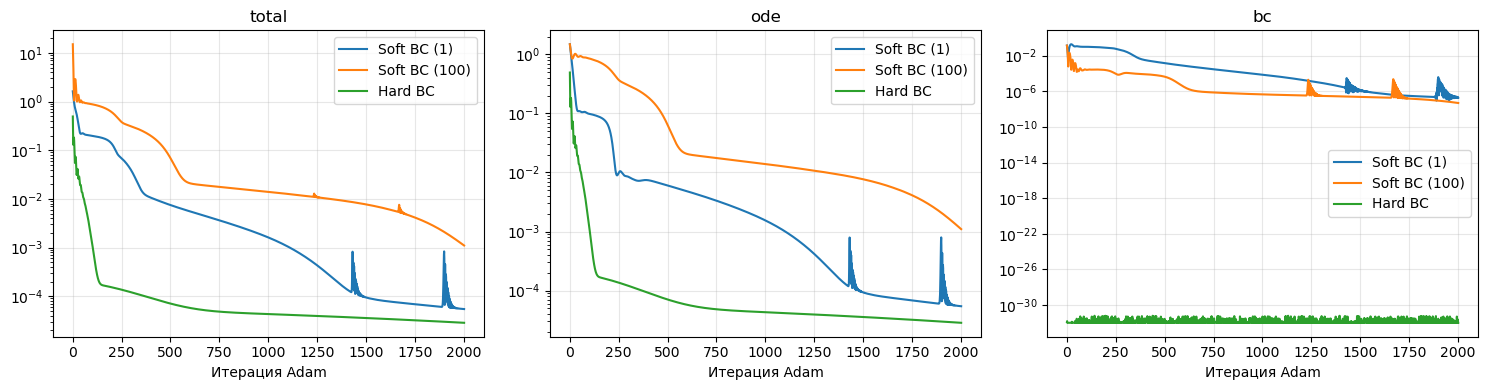

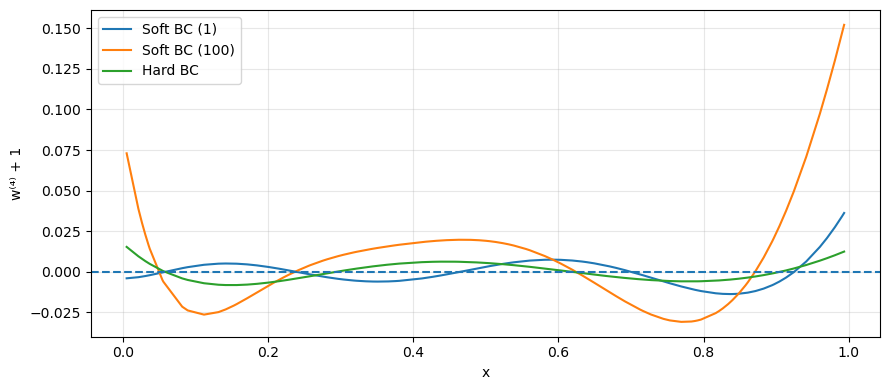

In [9]:
plot_quantities([('w1',"w'"),('w2',"w''"),('w3',"w3"),('w4','w⁽⁴⁾')],'03_derivatives.png')
plot_quantities([('w','Ошибка прогиба'),('w1','Ошибка угла'),('M','Ошибка момента'),('w4','Ошибка 4-й производной')],'05_absolute_errors.png',True)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,k in zip(axes,['total','ode','bc']):
    for name,h in histories.items():
        ax.semilogy(h.epoch,np.maximum(h[k],1e-32),label=name)
    ax.set_title(k); ax.set_xlabel('Итерация Adam'); ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig(out/'04_training_history.png',dpi=200); plt.show()
plt.figure(figsize=(9,4))
for name,r in results.items(): plt.plot(x_test.numpy().ravel(),r['w4']+1,label=name)
plt.axhline(0,ls='--'); plt.xlabel('x'); plt.ylabel('w⁽⁴⁾ + 1'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(out/'06_ode_residual.png',dpi=200); plt.show()


In [10]:
for name,df in [('metrics',metrics_df),('summary',summary_df),('boundary_conditions',bc_df)]:
    df.to_csv(out/f'{name}.csv',index=False,encoding='utf-8-sig')
for i,(name,model) in enumerate(models.items(),1):
    torch.save({'model_state_dict':model.state_dict(),'name':name,'mode':configs[name][0],'architecture':[1,32,32,1]},out/f'model_{i}.pth')
    histories[name].to_csv(out/f'history_{i}.csv',index=False)
print(out.resolve())


C:\Users\Polina\ML_SPBU_2026\Task_5\PINN_beam_results


## 8. Исследовательский вопрос

Малая среднеквадратическая ошибка аппроксимации прогиба балки не гарантирует высокой точности восстановления изгибающего момента. Это обусловлено тем, что изгибающий момент определяется второй производной функции прогиба, а операция дифференцирования способна существенно усиливать высокочастотные составляющие погрешности приближённого решения.

С математической точки зрения близость двух функций в норме пространства L₂ не обеспечивает близости их производных. Поэтому при оценке качества решения, полученного методом PINN, необходимо исследовать не только точность аппроксимации прогиба, но и точность восстановления угла поворота сечения, кривизны, изгибающего момента и производных более высоких порядков.

Выбор весовых коэффициентов граничных условий влияет на соотношение между точностью выполнения дифференциального уравнения и точностью удовлетворения граничным условиям. Увеличение веса граничных условий не обязательно приводит к улучшению решения во всей рассматриваемой области.

Использование встроенной формы граничных условий позволяет обеспечить их выполнение непосредственно за счёт математической конструкции приближённого решения, исключая необходимость введения соответствующих штрафных слагаемых в функцию потерь. Однако точность решения внутри области по-прежнему определяется качеством минимизации физической невязки.

Таким образом, для комплексной оценки эффективности PINN необходимо учитывать ошибки прогиба и его производных, невязку дифференциального уравнения, выполнение граничных условий и вычислительные затраты.